# The Criterion Closet, counted

Exploratory analysis of every Closet Picks visit (criterion.com/closet-picks), joined to the full collection list by spine number.

Inputs, all in `closet_data/` (produced by the scrapers):

- `collections.csv` — one row per visit: guest, date recorded
- `collection_picks.csv` — one row per pick: visit, order, spine
- `collection.csv` — the collection list: spine, title, director, country, year, box set flag
- `collection_details.csv` — per release: synopsis, runtime, color, language
- `cast.csv`, `credits.csv` — long tables, one row per person per release
- `boxset_films.csv` — which films sit inside which box set

Sections 1–3 build the working tables. Everything after is one question per section and can be run in any order.

In [1]:
import pandas as pd, numpy as np, re, json, itertools, collections
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('closet_data')
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## 1. Load and tidy

In [2]:
col  = pd.read_csv(DATA / 'collection.csv')
det  = pd.read_csv(DATA / 'collection_details.csv')
pk   = pd.read_csv(DATA / 'collection_picks.csv')
vis  = pd.read_csv(DATA / 'collections.csv')
cast = pd.read_csv(DATA / 'cast.csv').dropna(subset=['spine'])
cred = pd.read_csv(DATA / 'credits.csv').dropna(subset=['spine'])
bs   = pd.read_csv(DATA / 'boxset_films.csv')

# the collection, one row per spine
col = col.dropna(subset=['spine']).copy(); col['spine'] = col.spine.astype(int); col = col.drop_duplicates('spine').sort_values('spine')
det = det.dropna(subset=['spine']).copy(); det['spine'] = det.spine.astype(int); det = det.drop_duplicates('spine').set_index('spine')
col['year']    = col.year.fillna(col.spine.map(det.year))
col['country'] = col.country.fillna(col.spine.map(det.country))
col['c1']      = col.country.fillna('').str.split(',').str[0].str.strip()        # first-listed country
col['dec']     = (col.year // 10 * 10)
col['runtime'] = col.spine.map(det.runtime_min)
col['bw']      = col.spine.map(det.color).fillna('').str.lower().str.contains('black')
col['fid']     = col.url.str.extract(r'/films/(\d+)-')[0]
col['in_set']  = col.fid.isin(set(bs.film_url.str.extract(r'/films/(\d+)-')[0].dropna()))   # film only sold inside a box set
cast['spine'] = cast.spine.astype(int); cred['spine'] = cred.spine.astype(int)

# visits and picks. Re-derive guest names from the page title: the scraper's possessive regex ate the final s of "John Waters'"
vis['guest'] = vis.page_title.str.replace(r"(?:['’]s|['’])\s+(?:Mobile\s+)?Closet Picks.*$", '', regex=True).str.strip('​ ').str.strip()
vis['date'] = pd.to_datetime(vis.date_recorded)
p = pk.dropna(subset=['spine']).copy(); p['spine'] = p.spine.astype(int)
p = p.drop(columns=['guest']).merge(vis[['collection_id', 'guest', 'date', 'mobile_closet']], on='collection_id')
p = p.merge(col[['spine', 'year', 'c1', 'dec', 'director']].rename(columns={'year': 'fyear', 'director': 'dir'}), on='spine', how='left')
p = p.sort_values(['date', 'collection_id', 'pick_order']).reset_index(drop=True)

N = p.collection_id.nunique()
cnt = p.groupby('spine').collection_id.nunique()          # visits that took each film
col['n'] = col.spine.map(cnt).fillna(0).astype(int)

print(f'{N} visits, {len(p)} picks, {p.spine.nunique()} distinct films, {len(col)} spines in the collection')
print(f'picks without a spine (Janus Contemporaries etc.): {pk.spine.isna().sum()}')
p.head()

421 visits, 3010 picks, 846 distinct films, 1343 spines in the collection
picks without a spine (Janus Contemporaries etc.): 18


,collection_id,date_recorded,pick_order,film_id,spine,title,director,year,guest,date,mobile_closet,fyear,c1,dec,dir
0,645,"Sep 22, 2010",1,233,44,The Red Shoes,NaN,1948.0,Guillermo del Toro,2010-09-22,False,1948.0,United Kingdom,1940.0,Michael Powell and Emeric Pressburger
1,645,"Sep 22, 2010",2,151,5,The 400 Blows,NaN,1959.0,Guillermo del Toro,2010-09-22,False,1959.0,France,1950.0,François Truffaut
2,645,"Sep 22, 2010",3,603,57,Charade,NaN,1963.0,Guillermo del Toro,2010-09-22,False,1963.0,United States,1960.0,Stanley Donen
3,645,"Sep 22, 2010",4,2104,533,Crumb,NaN,1995.0,Guillermo del Toro,2010-09-22,False,1995.0,United States,1990.0,Terry Zwigoff
4,645,"Sep 22, 2010",5,27513,536,The Thin Red Line,NaN,1998.0,Guillermo del Toro,2010-09-22,False,1998.0,United States,1990.0,Terrence Malick


## 2. The shelf as it stood

Film year is the wrong clock: a 1965 film can enter the collection in 2008. Spine numbers are assigned in release order, so "what was on the shelf at a visit" is approximated by the spines released by then.
We estimate it as the third-highest spine seen in any pick up to that date (the max is fragile: Criterion updates old pages when a guest's request later gets a disc).

In [3]:
seen, shelf = [], {}
for cid, g in p.groupby('collection_id', sort=False):
    seen += list(g.spine); s = sorted(seen, reverse=True); shelf[cid] = s[2] if len(s) >= 3 else s[-1]
shelf = pd.Series(shelf, name='shelf'); p['shelf'] = p.collection_id.map(shelf)

ahead = p[p.spine > p.shelf + 15]
print(f'picks ahead of the shelf proxy: {len(ahead)} (films added to old pages after a later release)')
display(ahead[['guest', 'date', 'spine', 'title']])
p.groupby(p.date.dt.year).shelf.max().rename('shelf proxy at year end')

picks ahead of the shelf proxy: 16 (films added to old pages after a later release)


,guest,date,spine,title
19,Bill Hader,2011-03-02,1001,The Daytrippers
28,Alec Baldwin,2011-07-01,657,3:10 to Yuma
83,Edgar Wright,2014-02-01,745,Don’t Look Now
123,Volker Schlöndorff,2014-10-17,839,Boyhood
348,Ben Wheatley,2017-01-07,869,Rumble Fish
365,Flying Lotus,2017-03-19,888,Stalker
465,Euzhan Palcy,2017-11-05,953,A Dry White Season
578,Rodarte,2018-07-13,995,Polyester
646,Garrett Bradley,2021-10-07,1056,Moonstruck
647,Garrett Bradley,2021-10-07,1097,Love & Basketball


date
2010     536
2011     543
2012     619
2013     662
2014     780
2015     787
2016     839
2017     947
2018     995
2019     995
2021    1086
2022    1152
2023    1185
2024    1241
2025    1285
2026    1318
Name: shelf proxy at year end, dtype: int64

## 3. Headline numbers

In [4]:
standalone = col[(~col.in_set) & (~col.is_set)]
print(f'median picks per visit: {p.groupby("collection_id").size().median():.0f}')
print(f'films taken exactly once: {(cnt==1).sum()}   ten or more times: {(cnt>=10).sum()}')
print(f'top 20 films = {cnt.sort_values(ascending=False).head(20).sum()/len(p)*100:.1f}% of all picks')
print(f'standalone releases (not box sets, not inside one): {len(standalone)}; never taken: {(standalone.n==0).sum()} ({(standalone.n==0).mean()*100:.0f}%)')
print('never taken among spines 1-100:', standalone[(standalone.spine<=100)&(standalone.n==0)].title.tolist())
col.sort_values('n', ascending=False).head(20)[['spine','title','director','year','n']]

median picks per visit: 7
films taken exactly once: 236   ten or more times: 46
top 20 films = 9.3% of all picks
standalone releases (not box sets, not inside one): 936; never taken: 235 (25%)
never taken among spines 1-100: ['A Night to Remember', 'The Killer', 'Hard Boiled', 'Dead Ringers', 'RoboCop', 'Alphaville', 'Nanook of the North', 'Tokyo Drifter', 'The Most Dangerous Game', 'Insomnia', 'The Unbearable Lightness of Being', 'Le million', 'Chasing Amy', 'And God Created Woman', 'The Bank Dick', 'W. C. Fields—Six Short Films', 'The Harder They Come', 'Fiend Without a Face']


,spine,title,director,year,n
97,97,Do the Right Thing,Spike Lee,1989.0,21
140,140,8½,Federico Fellini,1963.0,18
723,724,All That Jazz,Bob Fosse,1979.0,18
43,44,The Red Shoes,Michael Powell and Emeric Pressburger,1948.0,16
218,219,La strada,Federico Fellini,1954.0,16
964,965,Wanda,Barbara Loden,1970.0,15
306,307,Naked,Mike Leigh,1993.0,14
863,864,Being There,Hal Ashby,1979.0,14
842,843,Punch-Drunk Love,Paul Thomas Anderson,2002.0,14
166,166,Down by Law,Jim Jarmusch,1986.0,13


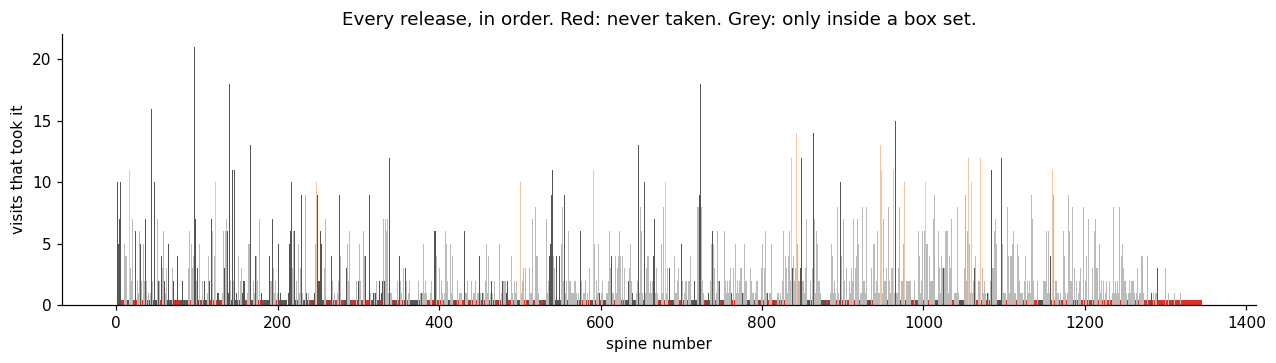

In [5]:
# the whole shelf: every spine as a bar
fig, ax = plt.subplots(figsize=(14, 3.2))
s = col.sort_values('spine')
colors = np.where(s.in_set, '#555', np.where(s.n == 0, '#d8322a', np.where(s.n >= 10, '#f1c7a2', '#bbb')))
ax.bar(s.spine, np.where(s.n == 0, 0.4, s.n), width=1, color=colors, linewidth=0)
ax.set_xlabel('spine number'); ax.set_ylabel('visits that took it'); ax.set_title('Every release, in order. Red: never taken. Grey: only inside a box set.')
plt.show()

## 4. Country × decade: what Criterion canonized vs what guests take

Expected picks for a (country, decade) cell = Σ over visits of (picks in that visit × the cell's share of the shelf at that visit).
Ratio = observed / expected. Cells with expected < 8 are dropped.

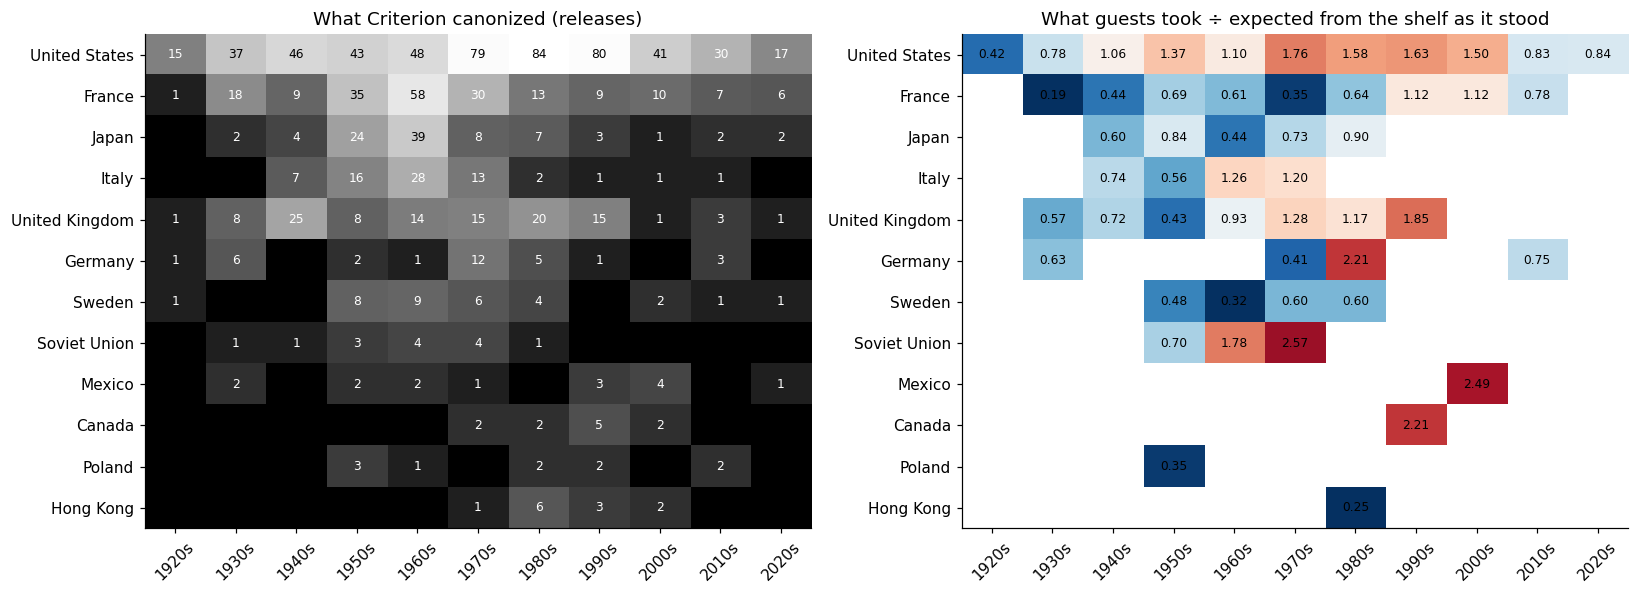

country-level ratio: {'United States': np.float64(1.34), 'France': np.float64(0.62), 'Japan': np.float64(0.67), 'Italy': np.float64(0.97), 'United Kingdom': np.float64(0.99), 'Germany': np.float64(0.74), 'Sweden': np.float64(0.44), 'Soviet Union': np.float64(1.53)}
decade-level ratio:  {1920: np.float64(0.53), 1930: np.float64(0.53), 1940: np.float64(0.82), 1950: np.float64(0.81), 1960: np.float64(0.82), 1970: np.float64(1.13), 1980: np.float64(1.24), 1990: np.float64(1.43), 2000: np.float64(1.39), 2010: np.float64(0.76), 2020: np.float64(1.45)}


,country,decade,picks,expected,ratio
4,France,1930,9,47.174761,0.190780
36,Sweden,1960,8,24.907546,0.321188
8,France,1970,27,77.200474,0.349739
14,Germany,1970,13,31.521744,0.412414
46,United States,1920,16,37.657448,0.424883
41,United Kingdom,1950,10,23.163320,0.431717
27,Japan,1960,48,108.216352,0.443556
5,France,1940,11,24.795130,0.443636
35,Sweden,1950,11,22.946638,0.479373
22,Italy,1950,25,44.356610,0.563614


In [6]:
films = col.dropna(subset=['dec'])[['spine', 'c1', 'dec']]
cache = {}
def shares(sh):
    if sh not in cache:
        f = films[films.spine <= sh]
        cache[sh] = (f.groupby(['c1','dec']).size()/len(f), f.c1.value_counts(normalize=True), f.dec.value_counts(normalize=True))
    return cache[sh]
exp_cell, exp_c, exp_d = collections.Counter(), collections.Counter(), collections.Counter()
for cid, g in p.groupby('collection_id'):
    cs, cc, cd = shares(shelf[cid]); n = len(g)
    for k, v in cs.items(): exp_cell[k] += v*n
    for k, v in cc.items(): exp_c[k] += v*n
    for k, v in cd.items(): exp_d[k] += v*n
obs = p.groupby(['c1','dec']).size()
grid = pd.DataFrame([(k[0], int(k[1]), int(obs.get(k,0)), e, obs.get(k,0)/e) for k, e in exp_cell.items() if e >= 8],
                    columns=['country','decade','picks','expected','ratio'])
countries = ['United States','France','Japan','Italy','United Kingdom','Germany','Sweden','Soviet Union','Mexico','Canada','Poland','Hong Kong']
decades = list(range(1920, 2030, 10))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
A = films[films.c1.isin(countries)].pivot_table(index='c1', columns='dec', values='spine', aggfunc='count', fill_value=0).reindex(index=countries, columns=decades).fillna(0)
im = axes[0].imshow(np.sqrt(A.values), cmap='Greys_r', aspect='auto'); axes[0].set_title('What Criterion canonized (releases)')
for i in range(len(countries)):
    for j in range(len(decades)):
        v = int(A.values[i, j]);
        if v: axes[0].text(j, i, v, ha='center', va='center', fontsize=8, color='black' if v > 30 else 'white')
B = grid.pivot(index='country', columns='decade', values='ratio').reindex(index=countries, columns=decades)
im2 = axes[1].imshow(np.log2(B.values), cmap='RdBu_r', vmin=-1.6, vmax=1.6, aspect='auto'); axes[1].set_title('What guests took ÷ expected from the shelf as it stood')
for i in range(len(countries)):
    for j in range(len(decades)):
        v = B.values[i, j]
        if not np.isnan(v): axes[1].text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8)
for ax in axes:
    ax.set_xticks(range(len(decades))); ax.set_xticklabels([f'{d}s' for d in decades], rotation=45); ax.set_yticks(range(len(countries))); ax.set_yticklabels(countries)
plt.tight_layout(); plt.show()

print('country-level ratio:', {c: round(p.c1.value_counts().get(c,0)/exp_c[c], 2) for c in countries[:8]})
print('decade-level ratio: ', {int(d): round((p.dec==d).sum()/exp_d[d], 2) for d in sorted(exp_d) if exp_d[d] >= 20})
grid[grid.expected >= 20].sort_values('ratio')

## 5. Reappraisal: do guests take what Criterion canonized late?

Within each decade of film history, split the collection into thirds by spine (early / mid / late release). Picks per 100 visits with the film on the shelf.

tercile,early,mid,late
dec,,,
1920.0,0.31,0.18,0.61
1930.0,0.30,0.46,0.28
1940.0,0.64,0.30,0.73
1950.0,0.63,0.42,0.65
1960.0,0.58,0.44,0.72
1970.0,0.58,0.69,1.22
1980.0,0.64,0.80,1.14
1990.0,0.68,0.96,1.56
2000.0,0.58,1.08,1.21


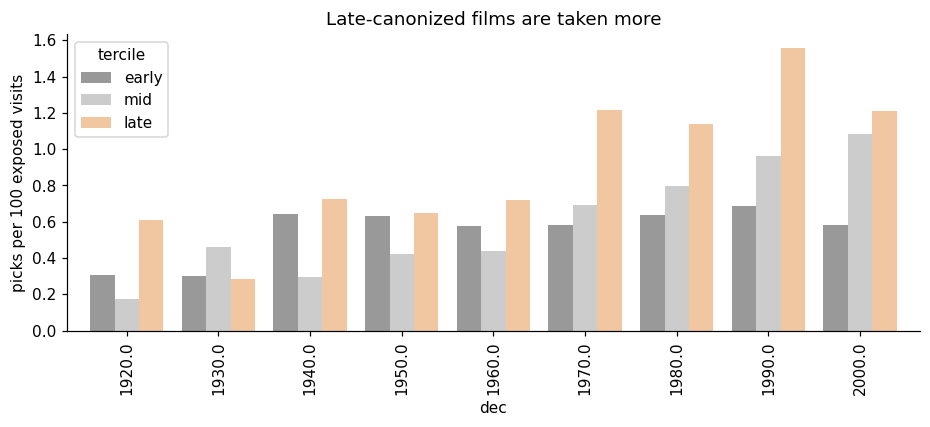

late-canonized old films taken most (film < 1995, spine > 900):


,spine,title,year,c1,n,exposed
964,965,Wanda,1970.0,United States,15,346
946,947,Shampoo,1975.0,United States,13,359
1055,1056,Moonstruck,1987.0,United States,12,337
1070,1071,Defending Your Life,1991.0,United States,12,337
947,948,The Princess Bride,1987.0,United States,11,357
986,987,Klute,1971.0,United States,11,345
962,963,To Sleep with Anger,1990.0,United States,11,346
1159,1160,Malcolm X,1992.0,United States,11,306
1017,1018,Paris Is Burning,1990.0,United States,11,338
1083,1084,Mirror,1975.0,Soviet Union,11,337


In [7]:
c = col.dropna(subset=['year']).copy()
c['tercile'] = c.groupby('dec').spine.transform(lambda s: pd.qcut(s.rank(method='first'), 3, labels=['early','mid','late']))
c['exposed'] = [(shelf >= s).sum() for s in c.spine]
c = c[c.exposed >= 20]; c['rate'] = c.n / c.exposed * 100
reap = c.pivot_table(index='dec', columns='tercile', values='rate', aggfunc='mean', observed=True).loc[1920:2000]
display(reap.round(2))
reap.plot.bar(figsize=(10, 3.5), color=['#999', '#ccc', '#f1c7a2'], width=0.8); plt.ylabel('picks per 100 exposed visits'); plt.title('Late-canonized films are taken more'); plt.show()
print('late-canonized old films taken most (film < 1995, spine > 900):')
c[(c.year < 1995) & (c.spine > 900)].sort_values('n', ascending=False).head(12)[['spine','title','year','c1','n','exposed']]

## 6. Same person, different day

In [8]:
sets = p.groupby('collection_id').apply(lambda g: set(g.spine))
rep = vis[vis.guest.duplicated(keep=False)].sort_values(['guest','date'])
for gname, grp in rep.groupby('guest'):
    a, b = [sets[c] for c in grp.collection_id]
    print(f'{gname:22s} {grp.date.dt.year.tolist()}  {len(a)} / {len(b)} picks, {len(a & b)} shared: {col.set_index("spine").title.reindex(list(a & b)).tolist()}')
pairs = sum(1 for i, j in itertools.combinations(sets.values, 2) if len(i & j) >= 2)
print(f'\nall visit pairs sharing >= 2 picks: {pairs} of {len(sets)*(len(sets)-1)//2}')

Ari Aster              [2023, 2025]  13 / 19 picks, 0 shared: []
Bill Hader             [2011, 2024]  7 / 13 picks, 1 shared: ['Salò, or The 120 Days of Sodom']
Edgar Wright           [2014, 2025]  4 / 4 picks, 0 shared: []
Guillermo del Toro     [2010, 2025]  8 / 9 picks, 1 shared: ['The Red Shoes']
Ira Sachs              [2016, 2025]  9 / 7 picks, 0 shared: []
Michael Cera           [2014, 2025]  3 / 7 picks, 0 shared: []

all visit pairs sharing >= 2 picks: 403 of 88410


/var/folders/r2/62xph3kj5rj_w51slp5lpvyc0000gn/T/ipykernel_3777/556826831.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sets = p.groupby('collection_id').apply(lambda g: set(g.spine))


## 7. Directors: breadth vs depth

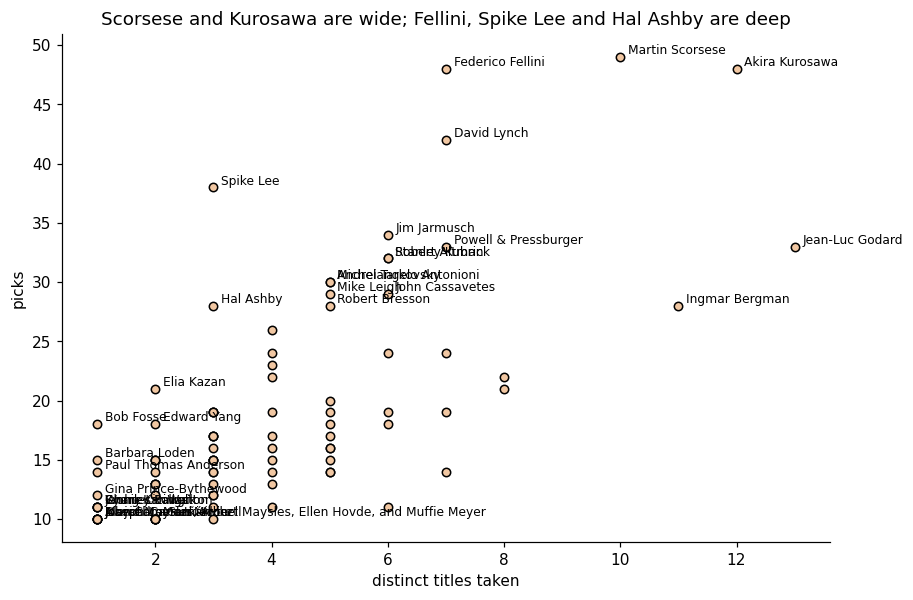

,dir,picks,titles
301,Martin Scorsese,49,10
4,Akira Kurosawa,48,12
126,Federico Fellini,48,7
97,David Lynch,42,7
405,Spike Lee,38,3
209,Jim Jarmusch,34,6
316,Michael Powell and Emeric Pressburger,33,7
203,Jean-Luc Godard,33,13
408,Stanley Kubrick,32,6
375,Robert Altman,32,6


In [9]:
dd = p.dropna(subset=['dir']).groupby('dir').agg(picks=('collection_id','size'), titles=('spine','nunique')).reset_index()
dd = dd[dd.picks >= 10].sort_values('picks', ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(dd.titles, dd.picks, s=30, color='#f1c7a2', edgecolor='k')
for r in dd.itertuples():
    if r.picks >= 28 or r.titles >= 10 or r.picks / r.titles >= 8: ax.annotate(r.dir.replace('Michael Powell and Emeric Pressburger', 'Powell & Pressburger'), (r.titles, r.picks), xytext=(5, 2), textcoords='offset points', fontsize=8)
ax.set_xlabel('distinct titles taken'); ax.set_ylabel('picks'); ax.set_title('Scorsese and Kurosawa are wide; Fellini, Spike Lee and Hal Ashby are deep'); plt.show()
dd.head(25)

## 8. Pick order

The shop pages list picks in the order they come off the shelf in the video (checked against the YouTube descriptions; the order correlates with neither alphabet nor spine). So position 1 is the first thing the guest reached for.

In [10]:
p['pop'] = p.spine.map(cnt)
po = p[p.pick_order <= 8].groupby('pick_order').agg(n=('spine','size'), mean_pop=('pop','mean'), share_rare=('pop', lambda x: (x <= 2).mean()), mean_year=('fyear','mean')).round(2)
display(po)
fl = np.array([(g['pop'].iloc[0], g['pop'].iloc[-1]) for _, g in p.groupby('collection_id') if len(g) >= 4])
print(f'visits with >= 4 picks: {len(fl)}; first pick taken by {fl[:,0].mean():.2f} other visits on average, last pick by {fl[:,1].mean():.2f}')

,n,mean_pop,share_rare,mean_year
pick_order,,,,
1,419,6.72,0.16,1973.30
2,419,6.16,0.19,1975.05
3,413,6.05,0.19,1976.06
4,393,5.74,0.25,1977.03
5,359,5.82,0.23,1977.02
6,290,5.88,0.22,1977.20
7,214,6.28,0.19,1976.40
8,151,5.48,0.23,1976.27


visits with >= 4 picks: 395; first pick taken by 6.75 other visits on average, last pick by 5.96


## 9. Vanity picks: the guest is in the film

In [11]:
def norm(s): return re.sub(r'[^a-z ]', '', str(s).lower()).strip()
people = {}
for sp, g in cast.groupby('spine'): people.setdefault(sp, set()).update(norm(x) for x in g.actor)
for sp, g in cred.groupby('spine'): people.setdefault(sp, set()).update(norm(x) for x in g.name)
van = []
for r in p.itertuples():
    names = [norm(x) for x in re.split(r' and |&|,', r.guest)]
    ppl = people.get(r.spine, set())
    if any(nm and any(nm == q or (len(nm.split()) >= 2 and nm in q) for q in ppl) for nm in names): van.append((r.guest.strip('\u200b'), r.title, r.date.year))
print(f'{len(van)} vanity picks of {len(p)} ({len(van)/len(p)*100:.1f}%), by {len(set(v[0] for v in van))} guests')
pd.DataFrame(van, columns=['guest','film','year'])

59 vanity picks of 3010 (2.0%), by 48 guests


,guest,film,year
0,Volker Schlöndorff,Coup de grâce,2014
1,Charlotte Rampling and Andrew Haigh,The Night Porter,2015
2,Charlotte Rampling and Andrew Haigh,Weekend,2015
3,Anna Karina,Pierrot le fou,2016
4,Anna Karina,A Woman Is a Woman,2016
5,Anna Karina,Made in U.S.A,2016
6,Euzhan Palcy,A Dry White Season,2017
7,Kemp Powers,One Night in Miami . . .,2021
8,Charlotte Gainsbourg,Antichrist,2022
9,Kyle MacLachlan,Blue Velvet,2022


## 10. Coherent or scattered visits?

In [12]:
rng = np.random.default_rng(0)
def modal(s): return s.value_counts().iloc[0] / len(s)
obs_c, exp_c2 = [], []
for cid, g in p.groupby('collection_id'):
    if len(g) < 4: continue
    obs_c.append(modal(g.c1)); f = films[films.spine <= g.shelf.iloc[0]]
    exp_c2 += [modal(f.sample(len(g), random_state=rng.integers(1e9)).c1) for _ in range(10)]
print(f'share of a visit from its most common country: actual {np.mean(obs_c):.3f}, random draws from the shelf {np.mean(exp_c2):.3f}')
thesis = [(g.guest.iloc[0], g.c1.mode()[0], len(g)) for _, g in p.groupby('collection_id') if len(g) >= 5 and modal(g.c1) >= 0.8]
print('single-country visits (>= 80%, >= 5 picks):', thesis)

share of a visit from its most common country: actual 0.555, random draws from the shelf 0.433
single-country visits (>= 80%, >= 5 picks): [('John Waters', 'United States', 5), ('Matthew Modine', 'United States', 7), ('James L. Brooks', 'United States', 5), ('Anna Karina', 'France', 5), ('Aubrey Plaza and Jeff Baena', 'United States', 17), ('Laura Albert & Jeff Feuerzeig', 'United States', 6), ('Marc Maron', 'United States', 11), ('Ron Shelton', 'United States', 6), ('Elvis Mitchell', 'United States', 6), ('Gregg Araki', 'United States', 6), ('Michael Shannon', 'United States', 6), ('Susanna Hoffs', 'United States', 6), ('Rickie Lee Jones', 'United States', 5), ('Mary Harron', 'United States', 6), ('Hideo Kojima', 'Japan', 8), ('Luis Guzmán', 'United States', 6), ('Neal Brennan', 'United States', 8), ('Cheryl Dunye', 'United States', 6), ('Viggo Mortensen', 'United States', 7), ('Paul Scheer', 'United States', 6), ('Jeremy Pope', 'United States', 5), ('André Holland', 'United States', 

## 11. Below the line

In [13]:
pc = p.merge(cast[cast.order <= 4][['spine','actor']], on='spine')
act = pc.groupby('actor').agg(visits=('collection_id','nunique'), films=('spine','nunique')).reset_index()
display(act[act.films >= 3].sort_values('visits', ascending=False).head(15))
for role, keys in [('cinematographer', ['cinematography','director of photography']), ('composer', ['music','original score','score']), ('writer', ['screenplay','written by','writer'])]:
    pr = p.merge(cred[cred.credit.str.lower().isin(keys)][['spine','name']], on='spine')
    g = pr.groupby('name').agg(visits=('collection_id','nunique'), films=('spine','nunique')).reset_index()
    print(role, g[g.films >= 3].sort_values('visits', ascending=False).head(8).values.tolist())

,actor,visits,films
362,Cary Grant,37,9
2415,Toshiro Mifune,35,9
1566,Marcello Mastroianni,34,5
31,Alain Delon,31,7
455,Claudia Cardinale,31,3
616,Dustin Hoffman,29,4
908,Harry Dean Stanton,28,5
1143,Jeanne Moreau,28,6
912,Harvey Keitel,27,7
323,Burt Lancaster,26,4


cinematographer [['Robby Müller', 43, 8], ['Giuseppe Rotunno', 35, 5], ['Michael Ballhaus', 28, 6], ['Henri Decaë', 26, 6], ['Dick Pope', 26, 4], ['Robert Yeoman', 22, 8], ['Raoul Coutard', 22, 10], ['Victor J. Kemper', 21, 4]]
composer [['Nino Rota', 36, 6], ['Fumio Hayasaka', 26, 4], ['John Lurie', 18, 3], ['Georges Delerue', 17, 5], ['Howard Shore', 15, 4], ['Giovanni Fusco', 15, 5], ['Alfred Newman', 14, 3], ['Ennio Morricone', 13, 5]]
writer [['Jim Jarmusch', 29, 5], ['Akira Kurosawa', 28, 7], ['Mike Leigh', 26, 4], ['Jean-Luc Godard', 26, 10], ['John Cassavetes', 26, 5], ['Robert Bresson', 25, 5], ['Hideo Oguni', 23, 5], ['David Cronenberg', 22, 4]]


## 12. Time to first pick, for releases that arrived during the series

In [14]:
visits_by_date = p.groupby('collection_id').agg(shelf=('shelf','first'), date=('date','first')).sort_values('date')
first = p.groupby('spine').date.min()
rows = []
for r in col[(col.spine > 540) & (~col.in_set)].itertuples():
    avail = visits_by_date[visits_by_date.shelf >= r.spine]
    if len(avail) == 0: continue
    rows.append((r.spine, r.title, r.year, (avail.date < first.get(r.spine, pd.Timestamp('2100'))).sum(), len(avail), r.spine in first.index))
t = pd.DataFrame(rows, columns=['spine','title','year','visits_until_first','visits_exposed','picked'])
print(f'{len(t)} standalone releases since 2010; {(t.picked & (t.visits_until_first <= 10)).sum()} taken within 10 exposed visits; {(~t.picked & (t.visits_exposed >= 100)).sum()} still untaken after 100+ visits')
print('never taken, longest exposed:'); display(t[~t.picked].sort_values('visits_exposed', ascending=False).head(12))
print('longest wait before the first pick:'); t[t.picked].sort_values('visits_until_first', ascending=False).head(8)

641 standalone releases since 2010; 148 taken within 10 exposed visits; 132 still untaken after 100+ visits
never taken, longest exposed:


,spine,title,year,visits_until_first,visits_exposed,picked
5,556,Senso,1954.0,411,411,False
35,587,Three Colors,NaN,411,411,False
56,618,Gray’s Anatomy,1997.0,411,411,False
55,617,And Everything Is Going Fine,2010.0,411,411,False
46,603,David Lean Directs Noël Coward,NaN,411,411,False
43,600,Anatomy of a Murder,1959.0,411,411,False
42,598,World on a Wire,1973.0,411,411,False
8,559,The Mikado,1939.0,411,411,False
33,585,Identification of a Woman,1982.0,411,411,False
21,572,"Léon Morin, Priest",1961.0,411,411,False


longest wait before the first pick:


,spine,title,year,visits_until_first,visits_exposed,picked
53,615,The Gold Rush,1942.0,384,411,True
167,771,"Two Days, One Night",2014.0,382,399,True
117,702,The Great Beauty,2013.0,377,404,True
204,820,Fantastic Planet,1973.0,363,381,True
81,652,Monsieur Verdoux,1947.0,362,409,True
288,923,Beyond the Hills,2012.0,357,359,True
172,777,The Brood,1979.0,356,399,True
319,959,In the Heat of the Night,1967.0,343,346,True


## 13. Smaller things: runtime, black-and-white, month, mobile closet

,shelf %,picks %
runtime,,
<90,20.7,15.6
90–110,43.0,42.2
110–130,20.8,22.7
130–160,10.1,13.3
>160,5.4,6.1


black & white: shelf 37.1%  picks 33.9%


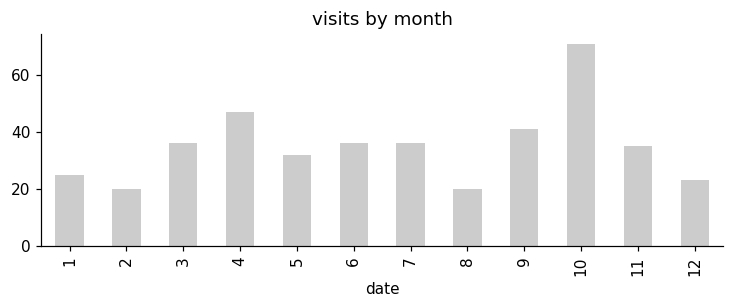

Sep–Oct vs rest: non-US share 0.53 vs 0.48; mean popularity 6.01 vs 6.00
mobile closet: 2 visits, mean popularity 6.39 vs 6.00 in the room


In [15]:
pp = p.merge(col[['spine','runtime','bw']], on='spine')
bins = [0, 90, 110, 130, 160, 400]; labels = ['<90', '90–110', '110–130', '130–160', '>160']
rt = pd.DataFrame({'shelf %': pd.cut(col.runtime, bins, labels=labels).value_counts(normalize=True).sort_index()*100,
                   'picks %': pd.cut(pp.runtime, bins, labels=labels).value_counts(normalize=True).sort_index()*100}).round(1)
display(rt); print(f'black & white: shelf {col.bw.mean()*100:.1f}%  picks {pp.bw.mean()*100:.1f}%')
vis.date.dt.month.value_counts().sort_index().plot.bar(figsize=(8, 2.5), color='#ccc', title='visits by month'); plt.show()
fall = p[p.date.dt.month.isin([9, 10])]; rest = p[~p.date.dt.month.isin([9, 10])]
print(f'Sep–Oct vs rest: non-US share {(fall.c1!="United States").mean():.2f} vs {(rest.c1!="United States").mean():.2f}; mean popularity {fall["pop"].mean():.2f} vs {rest["pop"].mean():.2f}')
mob = p[p.mobile_closet]; print(f'mobile closet: {mob.collection_id.nunique()} visits, mean popularity {mob["pop"].mean():.2f} vs {p[~p.mobile_closet]["pop"].mean():.2f} in the room')

## 15. A fairer leaderboard: picks per exposure

Raw counts favour films that have been on the shelf since 2010. Rate = picks per 100 visits that had the film available (shelf proxy). Restricted to films exposed to at least 60 visits.

In [16]:
expo = pd.Series({s: int((shelf >= s).sum()) for s in col.spine}, name='exposed')
lb = col.set_index('spine').join(expo); lb = lb[(lb.exposed >= 60) & (~lb.in_set)]
lb['rate'] = lb.n / lb.exposed * 100
display(lb.sort_values('rate', ascending=False).head(25)[['title','director','year','n','exposed','rate']].round(2))
print('biggest climbers vs raw rank (films outside the raw top 50 that make the rate top 25):')
raw50 = set(lb.sort_values('n', ascending=False).head(50).index); rate25 = lb.sort_values('rate', ascending=False).head(25)
rate25[~rate25.index.isin(raw50)][['title','year','n','exposed','rate']].round(2)

,title,director,year,n,exposed,rate
spine,,,,,,
1243,No Country for Old Men,Joel Coen and Ethan Coen,2007.0,8,171,4.68
1278,Flow,Gints Zilbalodis,2024.0,4,87,4.60
1235,Happiness,Todd Solondz,1998.0,8,188,4.26
843,Punch-Drunk Love,Paul Thomas Anderson,2002.0,14,374,3.74
947,Shampoo,Hal Ashby,1975.0,13,359,3.62
1160,Malcolm X,Spike Lee,1992.0,11,306,3.59
1270,Carnal Knowledge,Mike Nichols,1971.0,4,112,3.57
1271,You Can Count on Me,Kenneth Lonergan,2000.0,4,112,3.57
1056,Moonstruck,Norman Jewison,1987.0,12,337,3.56


biggest climbers vs raw rank (films outside the raw top 50 that make the rate top 25):


,title,year,n,exposed,rate
spine,,,,,
1278,Flow,2024.0,4,87,4.60
1270,Carnal Knowledge,1971.0,4,112,3.57
1271,You Can Count on Me,2000.0,4,112,3.57
1251,Drugstore Cowboy,1989.0,5,150,3.33
1241,Paper Moon,1973.0,6,183,3.28
1246,The Grifters,1990.0,5,165,3.03
1247,"Jo Jo Dancer, Your Life Is Calling",1986.0,5,165,3.03


## 16. Directors picked together

Films are too sparse for co-occurrence, but directors have more support. For each pair of directors, how many visits took both, against what independence would give. Support ≥ 6 visits.

In [17]:
dv = p.dropna(subset=['dir']).groupby('collection_id').dir.apply(set)
dcount = collections.Counter(d for s in dv for d in s)
pair = collections.Counter()
for s in dv:
    for a, b in itertools.combinations(sorted(s), 2): pair[(a, b)] += 1
rows = [(a, b, k, k * len(dv) / (dcount[a] * dcount[b])) for (a, b), k in pair.items() if k >= 6]
copick = pd.DataFrame(rows, columns=['director A', 'director B', 'visits together', 'lift']).sort_values('lift', ascending=False)
display(copick.head(25).round(2))
print('most-paired overall (by count):'); copick.sort_values('visits together', ascending=False).head(10).round(2)

,director A,director B,visits together,lift
1,Andrei Tarkovsky,Michelangelo Antonioni,6,3.22
2,David Lynch,Spike Lee,6,1.76
0,Federico Fellini,Martin Scorsese,8,1.70
3,Martin Scorsese,Spike Lee,6,1.64


most-paired overall (by count):


,director A,director B,visits together,lift
0,Federico Fellini,Martin Scorsese,8,1.70
1,Andrei Tarkovsky,Michelangelo Antonioni,6,3.22
2,David Lynch,Spike Lee,6,1.76
3,Martin Scorsese,Spike Lee,6,1.64


## 17. Does a famous guest move a film?

Join YouTube view counts (videos.csv) to visits by guest name. For picks made in the top-decile videos by views, compare the film's pick rate in the 60 visits before and the 60 visits after. Noisy by construction; read the aggregate, not the rows.

In [18]:
yt = pd.read_csv(DATA / 'videos.csv')
yt['g'] = yt.guest.str.lower().str.replace(r'[^a-z ]', '', regex=True).str.strip()
vis['g'] = vis.guest.str.lower().str.replace(r'[^a-z ]', '', regex=True).str.strip()
vv = vis.merge(yt[['g', 'view_count', 'upload_date']], on='g', how='left')
print(f'visits matched to a YouTube video: {vv.view_count.notna().sum()} of {len(vv)}')
order = vis.sort_values('date').collection_id.tolist(); pos = {c: i for i, c in enumerate(order)}
took = p.groupby('spine').collection_id.apply(set)
thr = vv.view_count.quantile(0.9); big = set(vv[vv.view_count >= thr].collection_id)
rows = []
for r in p[p.collection_id.isin(big)].itertuples():
    i = pos[r.collection_id]; before = order[max(0, i-60):i]; after = order[i+1:i+61]
    if len(before) < 40 or len(after) < 40: continue
    t = took.get(r.spine, set())
    rows.append((r.guest, r.title, sum(c in t for c in before) / len(before) * 100, sum(c in t for c in after) / len(after) * 100))
eff = pd.DataFrame(rows, columns=['guest', 'film', 'rate before', 'rate after'])
print(f'{len(eff)} picks in top-decile videos; mean rate before {eff["rate before"].mean():.2f}, after {eff["rate after"].mean():.2f} per 100 visits')
eff['delta'] = eff['rate after'] - eff['rate before']; eff.sort_values('delta', ascending=False).head(15).round(2)

visits matched to a YouTube video: 379 of 425
294 picks in top-decile videos; mean rate before 1.32, after 1.04 per 100 visits


,guest,film,rate before,rate after,delta
103,Hideo Kojima,Onibaba,0.00,5.00,5.00
197,Pamela Anderson,Wanda,1.67,6.67,5.00
154,Ayo Edebiri,To Sleep with Anger,0.00,5.00,5.00
158,Zoë Kravitz and Channing Tatum,Paris Is Burning,0.00,5.00,5.00
147,Winona Ryder,Matewan,0.00,3.33,3.33
269,Ari Aster,My Darling Clementine,0.00,3.33,3.33
122,Paul Giamatti,Blue Velvet,0.00,3.33,3.33
144,Winona Ryder,Ghost Dog: The Way of the Samurai,0.00,3.33,3.33
271,Margaret Qualley,Beau travail,0.00,3.33,3.33
107,Willem Dafoe,Pickpocket,0.00,3.33,3.33


## 18. Drift over the years

Share of picks that are American, and the median film year, by visit year, each against what the shelf of that year would give. A flat line means guests didn't change; the shelf did.

,picks,us share,median film year,shelf us share,shelf median year,us ratio
date,,,,,,
2010,8,0.50,1961.0,0.27,1964.0,1.84
2011,34,0.29,1969.5,0.28,1964.0,1.06
2012,13,0.15,1960.0,0.29,1965.0,0.53
2013,25,0.32,1963.0,0.30,1965.0,1.06
2014,69,0.25,1967.0,0.31,1966.0,0.79
2015,92,0.35,1974.0,0.31,1966.0,1.11
2016,98,0.46,1965.0,0.32,1966.0,1.43
2017,156,0.47,1971.0,0.34,1967.0,1.38
2018,96,0.52,1972.0,0.35,1967.0,1.49


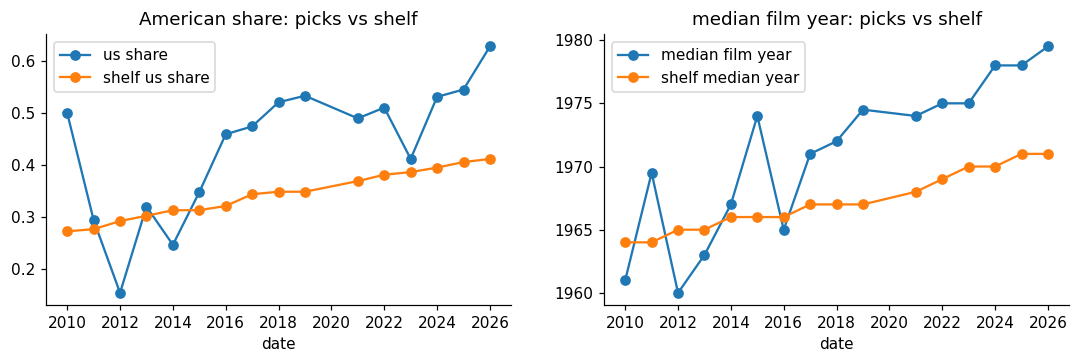

In [19]:
yr = p.groupby(p.date.dt.year)
drift = pd.DataFrame({'picks': yr.size(), 'us share': yr.apply(lambda g: (g.c1 == 'United States').mean()), 'median film year': yr.fyear.median()})
exp_us, exp_med = {}, {}
for y, g in yr:
    f = films[films.spine <= g.shelf.max()]; exp_us[y] = (f.c1 == 'United States').mean(); exp_med[y] = col[col.spine <= g.shelf.max()].year.median()
drift['shelf us share'] = pd.Series(exp_us); drift['shelf median year'] = pd.Series(exp_med)
drift['us ratio'] = drift['us share'] / drift['shelf us share']
display(drift.round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
drift[['us share', 'shelf us share']].plot(ax=ax[0], marker='o', title='American share: picks vs shelf'); drift[['median film year', 'shelf median year']].plot(ax=ax[1], marker='o', title='median film year: picks vs shelf'); plt.show()

## 19. Language, and English-language films from elsewhere

In [20]:
col['lang'] = col.spine.map(det.language).fillna('').str.split(',').str[0].str.strip()
pl = p.merge(col[['spine', 'lang']], on='spine')
lang = pd.DataFrame({'shelf %': col.lang.value_counts(normalize=True) * 100, 'picks %': pl.lang.value_counts(normalize=True) * 100}).dropna()
lang['ratio'] = lang['picks %'] / lang['shelf %']
display(lang[lang['shelf %'] >= 1].sort_values('ratio', ascending=False).round(2))
nonus_en = col[(col.lang == 'English') & (col.c1 != 'United States')]
print(f'English-language, non-American films: {len(nonus_en)} on the shelf, taken at {nonus_en.n.mean():.2f} picks each vs {col[col.c1 == "United States"].n.mean():.2f} for American and {col[col.lang != "English"].n.mean():.2f} for non-English')

,shelf %,picks %,ratio
lang,,,
Black and White/Color,1.27,2.13,1.68
Italian,4.10,5.22,1.27
English,48.99,61.26,1.25
Spanish,2.23,2.79,1.25
Japanese,6.85,5.32,0.78
French,14.22,10.73,0.75
German,2.46,1.76,0.72
Swedish,2.31,1.33,0.58
,7.22,0.63,0.09


English-language, non-American films: 166 on the shelf, taken at 2.40 picks each vs 2.92 for American and 1.70 for non-English


## 20. How wide is a visit? Spread of film years within each visit

In [21]:
spread = p.groupby('collection_id').agg(guest=('guest', 'first'), n=('spine', 'size'), span=('fyear', lambda s: s.max() - s.min()), iqr=('fyear', lambda s: s.quantile(.75) - s.quantile(.25)), lo=('fyear', 'min'), hi=('fyear', 'max'))
spread = spread[spread.n >= 5]
print(f'median span of film years within a visit (>= 5 picks): {spread.span.median():.0f} years; median IQR {spread.iqr.median():.0f}')
print('narrowest visits:'); display(spread.sort_values('span').head(10).round(0))
print('widest:'); spread.sort_values('span', ascending=False).head(6).round(0)

median span of film years within a visit (>= 5 picks): 51 years; median IQR 21
narrowest visits:


,guest,n,span,iqr,lo,hi
collection_id,,,,,,
475,Barry Levinson,6,8.0,5.0,1959.0,1967.0
977,Billy Eichner,5,9.0,6.0,1982.0,1991.0
801,Rosamund Pike,6,12.0,4.0,1961.0,1973.0
598,Guy Maddin,7,14.0,8.0,1960.0,1974.0
847,Matthew Broderick,6,16.0,6.0,1928.0,1944.0
579,Hideo Kojima,8,16.0,6.0,1949.0,1965.0
769,Robert Eggers,5,18.0,8.0,1961.0,1979.0
559,Susanna Hoffs,6,18.0,2.0,1966.0,1984.0
624,Kleber Mendonça Filho,6,18.0,12.0,1973.0,1991.0


widest:


,guest,n,span,iqr,lo,hi
collection_id,,,,,,
729,Anna Kendrick,5,94.0,8.0,1928.0,2022.0
926,Alex Winter,5,94.0,23.0,1928.0,2022.0
486,Cate Blanchett and Todd Field,13,93.0,38.0,1922.0,2015.0
1016,Zoe Kazan,14,92.0,53.0,1929.0,2021.0
667,Bill and Turner Ross,8,92.0,20.0,1928.0,2020.0
1001,Wes Anderson,9,91.0,25.0,1933.0,2024.0


## 21. Two people in the closet

In [22]:
duo = vis.guest.str.contains(r' and |&', regex=True)
pv = p.groupby('collection_id').agg(n=('spine', 'size'), pop=('pop', 'mean'), us=('c1', lambda s: (s == 'United States').mean()))
pv['duo'] = pv.index.map(dict(zip(vis.collection_id, duo)))
pv.groupby('duo').agg(visits=('n', 'size'), picks_per_visit=('n', 'mean'), mean_popularity=('pop', 'mean'), us_share=('us', 'mean')).round(2)

,visits,picks_per_visit,mean_popularity,us_share
duo,,,,
False,391,6.98,6.08,0.50
True,30,9.30,5.95,0.47


## 22. Reaching for the neighbour: adjacent spines within a visit

In [23]:
def adj(s, d=3): s = sorted(s); return sum(1 for a, b in zip(s, s[1:]) if b - a <= d)
obs_adj = sum(adj(s) for s in sets.values)
rng = np.random.default_rng(1); sims = []
for _ in range(200):
    tot = 0
    for cid, s in sets.items():
        f = films[films.spine <= shelf[cid]].spine.values; tot += adj(rng.choice(f, len(s), replace=False))
    sims.append(tot)
print(f'adjacent-spine pairs (within 3) across all visits: {obs_adj}; random draws from the shelf: {np.mean(sims):.1f} ± {np.std(sims):.1f}')
print('visits with the most adjacent pairs:'); pd.Series({cid: adj(s) for cid, s in sets.items()}).sort_values(ascending=False).head(8).rename(index=dict(zip(vis.collection_id, vis.guest)))

adjacent-spine pairs (within 3) across all visits: 135; random draws from the shelf: 60.7 ± 7.8
visits with the most adjacent pairs:


The Wolfpack          5
Elegance Bratton      3
Guillermo del Toro    3
Lav Diaz              3
Five Comics           3
Lucrecia Martel       3
Natasha Lyonne        3
Maggie Gyllenhaal     2
dtype: int64

## 23. Writer-directors

In [24]:
wr = cred[cred.credit.str.lower().isin(['screenplay', 'written by', 'writer', 'story'])].groupby('spine').name.apply(set)
dr = cred[cred.credit.str.lower() == 'director'].groupby('spine').name.apply(set)
col['auteur'] = [bool(wr.get(s, set()) & dr.get(s, set())) for s in col.spine]
pa = p.merge(col[['spine', 'auteur']], on='spine')
print(f'director also credited as writer: shelf {col.auteur.mean()*100:.1f}% of releases, picks {pa.auteur.mean()*100:.1f}%')
pa.groupby(pa.date.dt.year).auteur.mean().round(2).rename('auteur share of picks by year')

director also credited as writer: shelf 40.7% of releases, picks 44.1%


date
2010    0.38
2011    0.47
2012    0.62
2013    0.44
2014    0.51
2015    0.60
2016    0.47
2017    0.44
2018    0.43
2019    0.60
2021    0.43
2022    0.41
2023    0.47
2024    0.44
2025    0.42
2026    0.41
Name: auteur share of picks by year, dtype: float64

## 24. People: a helper

For any role table (actors from `cast`, crew from `credits`), three views per person: how many releases on the shelf they're in, how many of those have ever been taken, how many visits took one of them. "Pick rate" = visits per release on the shelf, which rewards people whose films get taken rather than people with many discs.

In [25]:
def people_table(role_df, name_col, min_films=3, order_max=None):
    d = role_df if order_max is None else role_df[role_df.order <= order_max]
    d = d[['spine', name_col]].drop_duplicates().rename(columns={name_col: 'name'})
    onshelf = d.groupby('name').spine.nunique().rename('releases')
    taken = d.merge(col[col.n > 0][['spine']], on='spine').groupby('name').spine.nunique().rename('releases taken')
    visits = d.merge(p[['spine', 'collection_id']], on='spine').groupby('name').collection_id.nunique().rename('visits')
    picks = d.merge(p[['spine']], on='spine').groupby('name').size().rename('picks')
    t = pd.concat([onshelf, taken, visits, picks], axis=1).fillna(0).astype(int)
    t['pick rate'] = (t.visits / t.releases).round(2); t['share taken'] = (t['releases taken'] / t.releases).round(2)
    return t[t.releases >= min_films]

def role(keys): return cred[cred.credit.str.lower().isin(keys)]
ROLES = {'director': ['director', 'directed by'], 'cinematographer': ['cinematography', 'director of photography', 'cinematographer', 'photography'],
         'screenwriter': ['screenplay', 'screenplay by', 'written by', 'writer', 'story', 'story by', 'script'],
         'composer': ['music', 'music by', 'original score', 'score', 'composer', 'original music'], 'editor': ['editing', 'editor', 'edited by', 'film editor'],
         'producer': ['producer', 'produced by', 'producers']}
print('credit labels in the data:', cred.credit.str.lower().value_counts().head(25).to_dict())

credit labels in the data: {'director': 1331, 'produced by': 732, 'screenplay': 720, 'producer': 660, 'music': 523, 'executive producer': 476, 'director of photography': 459, 'cinematography': 457, 'sound': 436, 'editor': 421, 'written by': 391, 'editing': 390, 'screenplay by': 331, 'production design': 242, 'edited by': 221, 'art director': 221, 'production designer': 204, 'assistant director': 197, 'music by': 196, 'associate producer': 192, 'costume designer': 161, 'production manager': 158, 'art direction': 148, 'costumes': 139, 'executive producers': 134}


## 25. Actors: most present on the shelf, most taken, highest pick rate

In [26]:
act = people_table(cast, 'actor', min_films=3, order_max=6)
print('most releases on the shelf (top-6 billed):'); display(act.sort_values('releases', ascending=False).head(15))
print('most visits took a film of theirs:'); display(act.sort_values('visits', ascending=False).head(20))
print('highest pick rate, at least 4 releases:'); act[act.releases >= 4].sort_values('pick rate', ascending=False).head(15)

most releases on the shelf (top-6 billed):


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Toshiro Mifune,17,9,35,35,2.06,0.53
Jeanne Moreau,14,7,29,31,2.07,0.50
Tatsuya Nakadai,12,7,19,21,1.58,0.58
Gunnar Björnstrand,11,6,15,15,1.36,0.55
Takashi Shimura,10,5,24,25,2.40,0.50
Cary Grant,10,9,37,41,3.70,0.90
Jean-Pierre Léaud,9,6,22,22,2.44,0.67
Chishu Ryu,9,4,23,24,2.56,0.44
Max von Sydow,9,5,10,10,1.11,0.56


most visits took a film of theirs:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Cary Grant,10,9,37,41,3.70,0.90
Toshiro Mifune,17,9,35,35,2.06,0.53
Marcello Mastroianni,7,5,34,38,4.86,0.71
Spike Lee,3,3,33,34,11.00,1.00
Roy R. Scheider,3,3,32,35,10.67,1.00
Claudia Cardinale,4,4,32,33,8.00,1.00
Alain Delon,7,7,31,34,4.43,1.00
Porter Hall,5,5,30,32,6.00,1.00
Jeanne Moreau,14,7,29,31,2.07,0.50


highest pick rate, at least 4 releases:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Claudia Cardinale,4,4,32,33,8.00,1.00
Burt Lancaster,4,4,26,26,6.50,1.00
Julie Christie,4,3,25,25,6.25,0.75
Porter Hall,5,5,30,32,6.00,1.00
Dustin Hoffman,5,4,29,29,5.80,0.80
Buck Henry,4,3,23,23,5.75,0.75
Ralph Bellamy,4,4,23,23,5.75,1.00
Nikolai Grinko,5,5,28,30,5.60,1.00
Marlon Brando,4,4,22,22,5.50,1.00


In [27]:
# leads vs supporting: does billing order matter to whether a film gets taken?
lead = people_table(cast, 'actor', min_films=3, order_max=2).add_suffix(' (lead)')
sup = people_table(cast[cast.order.between(3, 6)], 'actor', min_films=3).add_suffix(' (supporting)')
both = lead.join(sup, how='inner')
print('people with 3+ lead roles and 3+ supporting roles on the shelf, compared:')
both[['releases (lead)', 'visits (lead)', 'pick rate (lead)', 'releases (supporting)', 'visits (supporting)', 'pick rate (supporting)']].sort_values('visits (lead)', ascending=False).head(15)

people with 3+ lead roles and 3+ supporting roles on the shelf, compared:


,releases (lead),visits (lead),pick rate (lead),releases (supporting),visits (supporting),pick rate (supporting)
name,,,,,,
Jeanne Moreau,9,25,2.78,5,6,1.20
Giulietta Masina,3,17,5.67,3,0,0.00
Chishu Ryu,5,16,3.20,4,7,1.75
Harvey Keitel,3,16,5.33,4,13,3.25
Takashi Shimura,5,16,3.20,5,9,1.80
Jack Nicholson,4,10,2.50,3,5,1.67
Willem Dafoe,3,8,2.67,5,5,1.00
Hanna Schygulla,3,7,2.33,4,10,2.50
Max von Sydow,6,6,1.00,3,4,1.33


In [28]:
# most frequent co-stars among picked films (top-6 billed, pairs within a release, weighted by visits that took it)
c6 = cast[cast.order <= 6]
pairs = collections.Counter(); films_of = collections.defaultdict(set)
for sp, g in c6.groupby('spine'):
    w = int(cnt.get(sp, 0))
    if not w: continue
    for a, b in itertools.combinations(sorted(set(g.actor)), 2): pairs[(a, b)] += w; films_of[(a, b)].add(sp)
co = pd.DataFrame([(a, b, w, len(films_of[(a, b)])) for (a, b), w in pairs.items()], columns=['actor', 'co-star', 'visits', 'films']).sort_values('visits', ascending=False)
print('co-star pairs across 2+ picked films:'); co[co.films >= 2].head(20)

co-star pairs across 2+ picked films:


,actor,co-star,visits,films
317,Anatoly Solonitsyn,Nikolai Grinko,26,4
696,Chishu Ryu,Haruko Sugimura,22,3
12,Takashi Shimura,Toshiro Mifune,19,4
6900,Julie Christie,Warren Beatty,19,2
5202,Karl Malden,Marlon Brando,18,2
1715,Chishu Ryu,Setsuko Hara,17,2
1718,Haruko Sugimura,Setsuko Hara,17,2
7266,Divine,Edith Massey,17,4
426,Moira Shearer,Robert Helpmann,17,2
7143,Cary Grant,Ralph Bellamy,16,2


In [29]:
# actors over time: which actors' films are being taken more recently vs early in the series
pa = p.merge(c6[['spine', 'actor']], on='spine'); pa['era'] = np.where(pa.date.dt.year < 2022, '2010–2021', '2022–2026')
by_era = pa.groupby(['actor', 'era']).collection_id.nunique().unstack(fill_value=0)
by_era = by_era[(by_era.sum(axis=1) >= 12)]
tot = p.groupby(np.where(p.date.dt.year < 2022, '2010–2021', '2022–2026')).collection_id.nunique()
by_era['rate early'] = (by_era['2010–2021'] / tot['2010–2021'] * 100).round(1); by_era['rate late'] = (by_era['2022–2026'] / tot['2022–2026'] * 100).round(1)
by_era['shift'] = by_era['rate late'] - by_era['rate early']
print('rising (visits per 100, early vs late):'); display(by_era.sort_values('shift', ascending=False).head(10))
print('fading:'); by_era.sort_values('shift').head(10)

rising (visits per 100, early vs late):


era,2010–2021,2022–2026,rate early,rate late,shift
actor,,,,,
Denzel Washington,0,19,0.0,5.7,5.7
Spike Lee,3,30,3.5,9.0,5.5
Harvey Keitel,2,25,2.3,7.5,5.2
Laura Dern,0,17,0.0,5.1,5.1
Katharine Hepburn,0,16,0.0,4.8,4.8
Robert De Niro,2,23,2.3,6.9,4.6
Kelly Macdonald,0,15,0.0,4.5,4.5
Christopher Guest,1,19,1.2,5.7,4.5
Peter Falk,2,22,2.3,6.6,4.3


fading:


era,2010–2021,2022–2026,rate early,rate late,shift
actor,,,,,
Kirk Douglas,8,6,9.3,1.8,-7.5
Charles Chaplin,9,11,10.5,3.3,-7.2
Porter Hall,11,19,12.8,5.7,-7.1
Haruko Sugimura,9,12,10.5,3.6,-6.9
Tony Curtis,8,9,9.3,2.7,-6.6
Sy Richardson,7,5,8.1,1.5,-6.6
Veronica Lake,7,5,8.1,1.5,-6.6
Roy R. Scheider,11,21,12.8,6.3,-6.5
Barbara Steele,8,10,9.3,3.0,-6.3


## 26. Cinematographers

In [30]:
dp = people_table(role(ROLES['cinematographer']), 'name', min_films=3)
print('most releases shot:'); display(dp.sort_values('releases', ascending=False).head(12))
print('most visits:'); display(dp.sort_values('visits', ascending=False).head(15))
print('highest pick rate, 4+ releases:'); display(dp[dp.releases >= 4].sort_values('pick rate', ascending=False).head(12))
print('shot many, taken rarely:'); dp[dp.releases >= 6].sort_values('pick rate').head(10)

most releases shot:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Sven Nykvist,14,7,17,17,1.21,0.50
Raoul Coutard,14,11,31,35,2.21,0.79
Henri Decaë,12,8,28,31,2.33,0.67
Nestor Almendros,11,3,8,8,0.73,0.27
Robert Yeoman,9,8,22,22,2.44,0.89
Georges Périnal,9,2,8,8,0.89,0.22
Robby Müller,9,8,43,49,4.78,0.89
Ghislain Cloquet,8,4,9,10,1.12,0.50
Giuseppe Rotunno,7,5,35,35,5.00,0.71


most visits:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Robby Müller,9,8,43,49,4.78,0.89
Giuseppe Rotunno,7,5,35,35,5.00,0.71
Raoul Coutard,14,11,31,35,2.21,0.79
Michael Ballhaus,7,7,29,31,4.14,1.00
Henri Decaë,12,8,28,31,2.33,0.67
Dick Pope,5,4,26,27,5.20,0.80
Robert Yeoman,9,8,22,22,2.44,0.89
Walt Lloyd,3,3,21,22,7.00,1.00
Victor J. Kemper,4,4,21,21,5.25,1.00


highest pick rate, 4+ releases:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Victor J. Kemper,4,4,21,21,5.25,1.00
Dick Pope,5,4,26,27,5.20,0.80
Peter Deming,4,4,20,20,5.00,1.00
Giuseppe Rotunno,7,5,35,35,5.00,0.71
Robby Müller,9,8,43,49,4.78,0.89
Frederick Elmes,4,3,18,18,4.50,0.75
Tak Fujimoto,4,4,17,19,4.25,1.00
Miroslav Ondříček,4,4,17,18,4.25,1.00
Asakazu Nakai,5,4,21,22,4.20,0.80


shot many, taken rarely:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Nestor Almendros,11,3,8,8,0.73,0.27
Georges Périnal,9,2,8,8,0.89,0.22
Christian Matras,7,5,7,7,1.00,0.71
Ghislain Cloquet,8,4,9,10,1.12,0.50
Sven Nykvist,14,7,17,17,1.21,0.50
Victor Milner,6,4,12,13,2.00,0.67
Raoul Coutard,14,11,31,35,2.21,0.79
Gianni Di Venanzo,6,5,14,15,2.33,0.83
Henri Decaë,12,8,28,31,2.33,0.67


In [31]:
# director–cinematographer partnerships among picked films
dd_ = role(ROLES['director'])[['spine', 'name']].rename(columns={'name': 'director'}); dp_ = role(ROLES['cinematographer'])[['spine', 'name']].rename(columns={'name': 'dp'})
team = dd_.merge(dp_, on='spine').drop_duplicates()
tt = team.merge(col[['spine', 'n']], on='spine').groupby(['director', 'dp']).agg(releases=('spine', 'nunique'), visits=('n', 'sum')).reset_index()
tt[tt.releases >= 2].sort_values('visits', ascending=False).head(20)

,director,dp,releases,visits
594,Mike Leigh,Dick Pope,5,27
385,Jim Jarmusch,Robby Müller,4,25
374,Jean-Luc Godard,Raoul Coutard,10,24
12,Akira Kurosawa,Asakazu Nakai,5,22
128,Charles Chaplin,Roland Totheroh,5,18
557,Martin Scorsese,Michael Ballhaus,3,18
240,Federico Fellini,Otello Martelli,4,17
827,Wes Anderson,Robert Yeoman,8,17
318,Ingmar Bergman,Sven Nykvist,12,17
20,Alan J. Pakula,Gordon Willis,2,15


In [32]:
# colour vs black-and-white by cinematographer era: share of B&W among picked films by film decade, vs shelf
bwp = p.merge(col[['spine', 'bw']], on='spine')
pd.DataFrame({'shelf % B&W': col.groupby('dec').bw.mean() * 100, 'picks % B&W': bwp.groupby('dec').bw.mean() * 100}).loc[1930:1990].round(1)

,shelf % B&W,picks % B&W
dec,,
1930.0,94.9,99.0
1940.0,89.4,80.8
1950.0,80.5,86.1
1960.0,63.2,62.6
1970.0,9.4,6.4
1980.0,5.5,8.2
1990.0,5.4,4.0


## 27. Screenwriters

In [33]:
wr_ = people_table(role(ROLES['screenwriter']), 'name', min_films=3)
print('most visits:'); display(wr_.sort_values('visits', ascending=False).head(20))
print('highest pick rate, 4+ releases:'); display(wr_[wr_.releases >= 4].sort_values('pick rate', ascending=False).head(12))
# writers who are not the director of the film (pure screenwriters)
dirs_by_spine = role(ROLES['director']).groupby('spine').name.apply(set)
w = role(ROLES['screenwriter'])[['spine', 'name']].drop_duplicates()
w['is_director'] = [n in dirs_by_spine.get(s, set()) for s, n in zip(w.spine, w.name)]
pure = people_table(w[~w.is_director], 'name', min_films=2)
print('writers who did not direct, most visits:'); pure.sort_values('visits', ascending=False).head(15)

most visits:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Federico Fellini,10,4,33,36,3.30,0.40
David Lynch,6,6,33,34,5.50,1.00
Akira Kurosawa,12,8,30,32,2.50,0.67
Jim Jarmusch,5,5,29,31,5.80,1.00
John Cassavetes,6,5,26,27,4.33,0.83
Jean-Luc Godard,11,10,26,28,2.36,0.91
Mike Leigh,5,4,26,27,5.20,0.80
Robert Bresson,7,5,25,28,3.57,0.71
Yasujiro Ozu,5,4,23,24,4.60,0.80


highest pick rate, 4+ releases:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Jim Jarmusch,5,5,29,31,5.80,1.00
Kogo Noda,4,4,23,24,5.75,1.00
David Lynch,6,6,33,34,5.50,1.00
Mike Leigh,5,4,26,27,5.20,0.80
Brunello Rondi,4,2,19,19,4.75,0.50
Yasujiro Ozu,5,4,23,24,4.60,0.80
Albert Brooks,4,3,18,19,4.50,0.75
Stanley Kubrick,4,4,18,19,4.50,1.00
John Cassavetes,6,5,26,27,4.33,0.83


writers who did not direct, most visits:


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Kogo Noda,4,4,23,24,5.75,1.00
Hideo Oguni,7,5,23,23,3.29,0.71
Suso Cecchi D’Amico,6,3,20,21,3.33,0.50
Ennio Flaiano,6,4,20,22,3.33,0.67
Shinobu Hashimoto,7,5,20,20,2.86,0.71
Tullio Pinelli,7,3,19,20,2.71,0.43
Brunello Rondi,4,2,19,19,4.75,0.50
Tonino Guerra,5,4,19,19,3.80,0.80
Mardik Martin,2,2,17,17,8.50,1.00


In [34]:
# adapted or original? 'Based on' credits as a proxy for adaptation
based = cred[cred.credit.str.lower().str.startswith('based on')].spine.unique()
col['adapted'] = col.spine.isin(based)
pad = p.merge(col[['spine', 'adapted']], on='spine')
print(f'releases with a "based on" credit: shelf {col.adapted.mean()*100:.1f}%, picks {pad.adapted.mean()*100:.1f}%')
print('most-taken adapted films:'); col[col.adapted].sort_values('n', ascending=False).head(10)[['spine', 'title', 'year', 'n']]

releases with a "based on" credit: shelf 20.0%, picks 18.7%
most-taken adapted films:


,spine,title,year,n
863,864,Being There,1979.0,14
1159,1160,Malcolm X,1992.0,11
373,374,Bicycle Thieves,1948.0,11
280,281,Jules and Jim,1962.0,10
896,897,Barry Lyndon,1975.0,10
1133,1134,Raging Bull,1980.0,9
1242,1243,No Country for Old Men,2007.0,8
851,852,Black Girl,1966.0,8
720,721,Love Streams,1984.0,8
924,925,Midnight Cowboy,1969.0,8


## 28. Composers, editors, producers

In [35]:
for r in ['composer', 'editor', 'producer']:
    t = people_table(role(ROLES[r]), 'name', min_films=3)
    print(f'--- {r}: most visits'); display(t.sort_values('visits', ascending=False).head(10))
    print(f'--- {r}: highest pick rate (4+ releases)'); display(t[t.releases >= 4].sort_values('pick rate', ascending=False).head(8))

--- composer: most visits


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Nino Rota,12,7,39,41,3.25,0.58
Howard Shore,9,6,28,29,3.11,0.67
Fumio Hayasaka,7,4,26,26,3.71,0.57
John Lurie,4,4,24,24,6.00,1.00
Carter Burwell,4,3,20,20,5.00,0.75
Georges Delerue,11,6,20,21,1.82,0.55
Elmer Bernstein,3,3,18,18,6.00,1.00
Dave Grusin,3,3,18,18,6.00,1.00
Alessandro Cicognini,5,3,18,18,3.60,0.60


--- composer: highest pick rate (4+ releases)


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
John Lurie,4,4,24,24,6.00,1.00
Carter Burwell,4,3,20,20,5.00,0.75
Fumio Hayasaka,7,4,26,26,3.71,0.57
Alessandro Cicognini,5,3,18,18,3.60,0.60
Nino Rota,12,7,39,41,3.25,0.58
Howard Shore,9,6,28,29,3.11,0.67
Mark Mothersbaugh,4,4,12,12,3.00,1.00
Hans Zimmer,4,3,12,12,3.00,0.75


--- editor: most visits


...

,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Melody London,4,4,25,25,6.25,1.00
Tony Lawson,4,4,18,18,4.50,1.00
Reginald Mills,6,5,26,29,4.33,0.83
Eraldo Da Roma,9,6,36,39,4.00,0.67
Roderick Jaynes,4,3,16,16,4.00,0.75
Thelma Schoonmaker,5,4,19,19,3.80,0.80
Raymond Lamy,4,4,14,15,3.50,1.00
Sam O’Steen,4,4,14,14,3.50,1.00


--- producer: most visits


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Spike Lee,5,4,45,50,9.00,0.80
Scott Rudin,12,9,30,32,2.50,0.75
Christine Vachon,4,4,26,26,6.50,1.00
Simon Channing-Williams,4,3,24,25,6.00,0.75
Alfonso Cuarón,4,4,22,22,5.50,1.00
Ethan Coen,5,4,20,22,4.00,0.80
Sojiro Motoki,5,3,20,20,4.00,0.60
Anatole Dauman,11,9,18,19,1.64,0.82
Stanley Kubrick,3,3,18,18,6.00,1.00


--- producer: highest pick rate (4+ releases)


,releases,releases taken,visits,picks,pick rate,share taken
name,,,,,,
Spike Lee,5,4,45,50,9.00,0.80
Christine Vachon,4,4,26,26,6.50,1.00
Simon Channing-Williams,4,3,24,25,6.00,0.75
Alfonso Cuarón,4,4,22,22,5.50,1.00
Alain Sarde,4,4,17,18,4.25,1.00
Andrew Braunsberg,4,4,17,18,4.25,1.00
Sojiro Motoki,5,3,20,20,4.00,0.60
Ethan Coen,5,4,20,22,4.00,0.80


## 29. Crew completeness and cast size

In [36]:
has = pd.DataFrame({r: col.spine.isin(role(k).spine) for r, k in ROLES.items()}); has['cast'] = col.spine.isin(cast.spine)
print('share of standalone releases with each credit type:'); display((has[~col.in_set.values & ~col.is_set.values].mean() * 100).round(1))
cs = cast.groupby('spine').size().rename('cast size')
pcs = p.merge(cs, left_on='spine', right_index=True)
print(f'cast size (listed): shelf median {cs.median():.0f}, picked films median {pcs["cast size"].median():.0f}')

share of standalone releases with each credit type:


director           100.0
cinematographer     74.3
screenwriter        76.7
composer            52.9
editor              75.3
producer            79.3
cast                97.0
dtype: float64

cast size (listed): shelf median 10, picked films median 12


## 30. Scratch

Ideas not yet run: directors picked together across visits (a co-pick network at the director level, which has more support than films); guests' own era (do people pick films from their teenage years?) — needs birth years; whether a film's pick rate changes after a famous guest takes it.

In [37]:
# scratch